In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path
import pandas as pd

file_path = Path("../data/SolarPrediction.csv")

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

Dataset shape: (32686, 11)

Column names:
['UNIXTime', 'Data', 'Time', 'Radiation', 'Temperature', 'Pressure', 'Humidity', 'WindDirection(Degrees)', 'Speed', 'TimeSunRise', 'TimeSunSet']

First 5 rows:


,UNIXTime,Data,Time,Radiation,Temperature,Pressure,Humidity,WindDirection(Degrees),Speed,TimeSunRise,TimeSunSet
0,1475229326,9/29/2016 12:00:00 AM,23:55:26,1.21,48,30.46,59,177.39,5.62,06:13:00,18:13:00
1,1475229023,9/29/2016 12:00:00 AM,23:50:23,1.21,48,30.46,58,176.78,3.37,06:13:00,18:13:00
2,1475228726,9/29/2016 12:00:00 AM,23:45:26,1.23,48,30.46,57,158.75,3.37,06:13:00,18:13:00
3,1475228421,9/29/2016 12:00:00 AM,23:40:21,1.21,48,30.46,60,137.71,3.37,06:13:00,18:13:00
4,1475228124,9/29/2016 12:00:00 AM,23:35:24,1.17,48,30.46,62,104.95,5.62,06:13:00,18:13:00



Data types:
UNIXTime                    int64
Data                          str
Time                          str
Radiation                 float64
Temperature                 int64
Pressure                  float64
Humidity                    int64
WindDirection(Degrees)    float64
Speed                     float64
TimeSunRise                   str
TimeSunSet                    str
dtype: object

Missing values:
UNIXTime                  0
Data                      0
Time                      0
Radiation                 0
Temperature               0
Pressure                  0
Humidity                  0
WindDirection(Degrees)    0
Speed                     0
TimeSunRise               0
TimeSunSet                0
dtype: int64


In [3]:
data = df.copy()
data["DateParsed"] = pd.to_datetime(
    data["Data"],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="coerce"
)
data["Datetime"] = pd.to_datetime(
    data["DateParsed"].dt.strftime("%Y-%m-%d")
    + " "
    + data["Time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

data["SunriseTime"] = pd.to_timedelta(data["TimeSunRise"])
data["SunsetTime"] = pd.to_timedelta(data["TimeSunSet"])

display(
    data[["Datetime", "TimeSunRise", "TimeSunSet",
          "SunriseTime", "SunsetTime"]].head()
)

data = data.sort_values("Datetime").reset_index(drop=True)

data["DateOnly"] = data["Datetime"].dt.date
data["Hour"] = data["Datetime"].dt.hour

print("Dataset shape:", data.shape)
print("Invalid dates:", data["DateParsed"].isna().sum())
print("Invalid datetimes:", data["Datetime"].isna().sum())
print("First observation:", data["Datetime"].min())
print("Last observation:", data["Datetime"].max())



,Datetime,TimeSunRise,TimeSunSet,SunriseTime,SunsetTime
0,2016-09-29 23:55:26,06:13:00,18:13:00,0 days 06:13:00,0 days 18:13:00
1,2016-09-29 23:50:23,06:13:00,18:13:00,0 days 06:13:00,0 days 18:13:00
2,2016-09-29 23:45:26,06:13:00,18:13:00,0 days 06:13:00,0 days 18:13:00
3,2016-09-29 23:40:21,06:13:00,18:13:00,0 days 06:13:00,0 days 18:13:00
4,2016-09-29 23:35:24,06:13:00,18:13:00,0 days 06:13:00,0 days 18:13:00


Dataset shape: (32686, 17)
Invalid dates: 0
Invalid datetimes: 0
First observation: 2016-09-01 00:00:08
Last observation: 2016-12-31 23:55:01


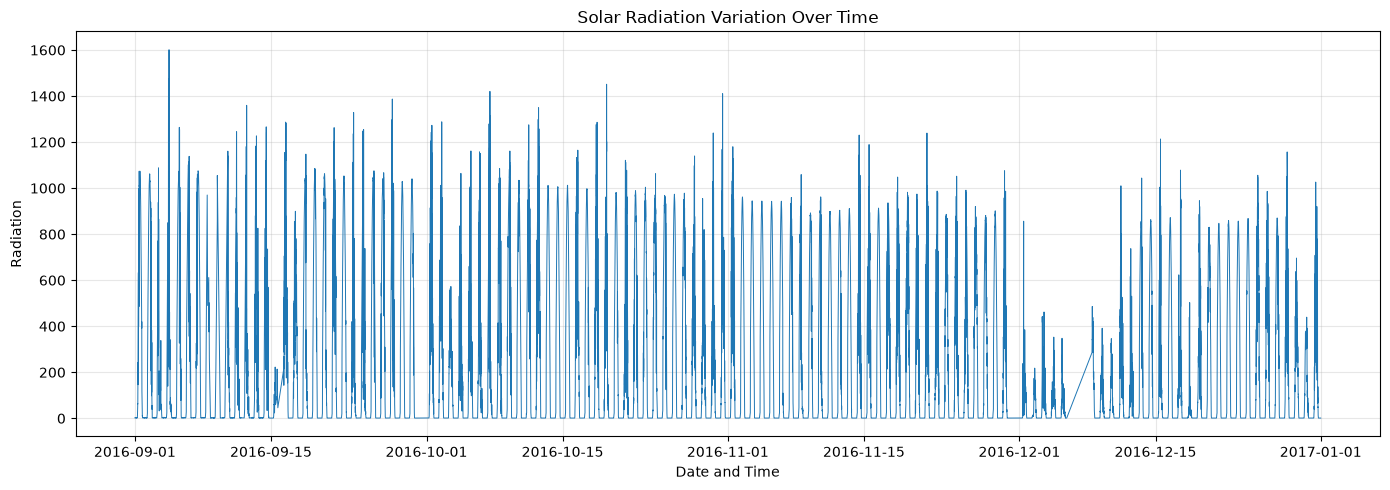

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    data["Datetime"],
    data["Radiation"],
    linewidth=0.7
)

plt.title("Solar Radiation Variation Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Radiation")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../plots/01_radiation_over_time.png", dpi=200)
plt.show()

In [5]:
peak_index = data["Radiation"].idxmax()
peak = data.loc[peak_index]

print("Maximum radiation:", peak["Radiation"])
print("Date and time:", peak["Datetime"])
print("Temperature:", peak["Temperature"])
print("Humidity:", peak["Humidity"])
print("Wind speed:", peak["Speed"])

Maximum radiation: 1601.26
Date and time: 2016-09-04 12:15:04
Temperature: 61
Humidity: 93
Wind speed: 9.0


In [6]:
daily_stats = data.groupby("DateOnly")["Radiation"].agg(
    ["max", "mean"]
)

daily_stats.columns = ["Daily_Max", "Daily_Mean"]

display(daily_stats.head(10))

,Daily_Max,Daily_Mean
DateOnly,,
2016-09-01,1073.71,298.451600
2016-09-02,1062.01,333.471219
2016-09-03,1088.09,123.974574
2016-09-04,1601.26,153.584321
2016-09-05,1264.07,306.065125
2016-09-06,1138.21,310.643781
2016-09-07,1075.35,151.374677
2016-09-08,970.12,25.105563
2016-09-09,1054.99,19.137236


In [12]:
top_5_days = daily_stats.sort_values(
    by="Daily_Mean",
    ascending=False
).head(5)

display(top_5_days)
print("Number of dates:", len(daily_stats))

,Daily_Max,Daily_Mean
DateOnly,,
2016-09-19,1085.75,335.504400
2016-09-02,1062.01,333.471219
2016-09-22,1053.17,325.515880
2016-09-25,1075.29,319.921514
2016-09-28,1029.30,312.400390


Number of dates: 118


In [ ]:
all_dates = pd.date_range(
    start=data["Datetime"].min().normalize(),
    end=data["Datetime"].max().normalize(),
    freq="D"
).date

observed_dates = set(data["DateOnly"])
missing_dates = sorted(set(all_dates) - observed_dates)

print("Expected calendar days:", len(all_dates))
print("Observed dates:", len(observed_dates))
print("Missing dates:", len(missing_dates))
print("Missing dates:", missing_dates)

Expected calendar days: 122
Observed dates: 118
Missing dates: 4
Missing dates: [datetime.date(2016, 9, 30), datetime.date(2016, 11, 30), datetime.date(2016, 12, 6), datetime.date(2016, 12, 7)]


In [14]:
sunrise = pd.to_timedelta(peak["TimeSunRise"])
sunset = pd.to_timedelta(peak["TimeSunSet"])

peak_time = pd.to_timedelta(peak["Datetime"].strftime("%H:%M:%S"))

time_after_sunrise = peak_time - sunrise

print("Sunrise:", sunrise)
print("Peak time:", peak_time)
print("Time after sunrise:", time_after_sunrise)
print("Sunset:", sunset)

Sunrise: 0 days 06:08:00
Peak time: 0 days 12:15:04
Time after sunrise: 0 days 06:07:04
Sunset: 0 days 18:35:00


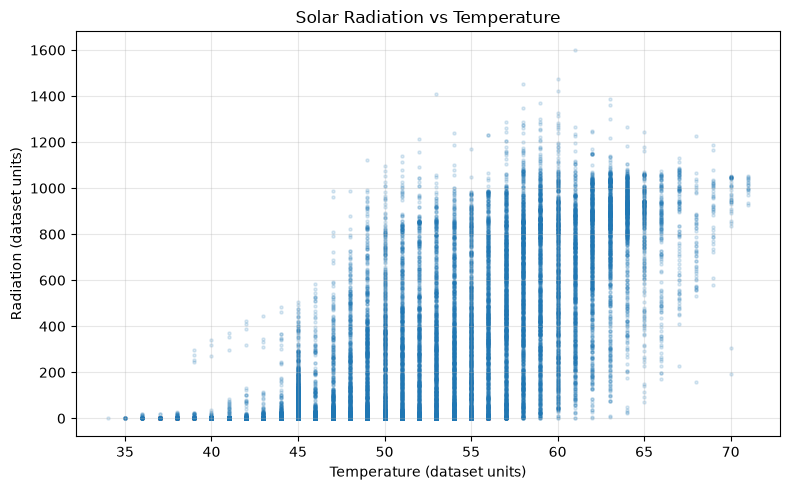

Temperature-radiation correlation: 0.7349547554357316


In [16]:
import matplotlib.pyplot as plt

temp_data = data[["Temperature", "Radiation"]].dropna()
plt.figure(figsize=(8, 5))

plt.scatter(
    temp_data["Temperature"],
    temp_data["Radiation"],
    alpha=0.15,
    s=5
)

plt.title("Solar Radiation vs Temperature")
plt.xlabel("Temperature (dataset units)")
plt.ylabel("Radiation (dataset units)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../plots/02_radiation_vs_temperature.png", dpi=200)
plt.show()

correlation = temp_data["Temperature"].corr(temp_data["Radiation"])
print("Temperature-radiation correlation:", correlation)

In [17]:
humidity_data = data[["Humidity", "Radiation"]].dropna()

plt.figure(figsize=(8, 5))

plt.scatter(
    humidity_data["Humidity"],
    humidity_data["Radiation"],
    alpha=0.3,
    s=10
)

plt.title("Solar Radiation vs Humidity")
plt.xlabel("Humidity (dataset units)")
plt.ylabel("Radiation (dataset units)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../plots/03_radiation_vs_humidity.png", dpi=200)
plt.show()

correlation = humidity_data["Humidity"].corr(
    humidity_data["Radiation"]
)

print("Humidity-radiation correlation:", correlation)

NameError: name 'data' is not defined

In [6]:
environment_cols = [
    "Temperature",
    "Pressure",
    "Humidity",
    "WindDirection(Degrees)",
    "Speed"
]

correlations = data[environment_cols + ["Radiation"]].corr(
    numeric_only=True
)["Radiation"]

correlations = correlations.drop("Radiation")

correlations = correlations.sort_values(
    ascending=False
)

display(correlations.to_frame(name="Radiation_Correlation"))

NameError: name 'data' is not defined

In [4]:
columns = [
    "Radiation",
    "Temperature",
    "Pressure",
    "Humidity",
    "Speed"
]

corr_matrix = data[columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Between Solar Radiation and Environmental Variables")
plt.tight_layout()
plt.savefig("../plots/04_correlation_heatmap.png", dpi=200)
plt.show()


NameError: name 'data' is not defined

In [24]:
hourly_stats = data.groupby("Hour")["Radiation"].agg(
    ["mean", "median", "max", "count"]
)

hourly_stats.columns = [
    "Average_Radiation",
    "Median_Radiation",
    "Maximum_Radiation",
    "Number_of_Readings"
]

display(hourly_stats.round(2))

,Average_Radiation,Median_Radiation,Maximum_Radiation,Number_of_Readings
Hour,,,,
0,1.32,1.22,3.82,1207
1,1.38,1.23,4.33,1382
2,1.39,1.23,4.54,1384
3,1.37,1.23,3.90,1384
4,1.36,1.22,3.63,1388
5,1.36,1.22,4.28,1380
6,9.81,5.33,139.01,1361
7,128.77,63.75,538.79,1355
8,370.39,403.45,828.53,1356


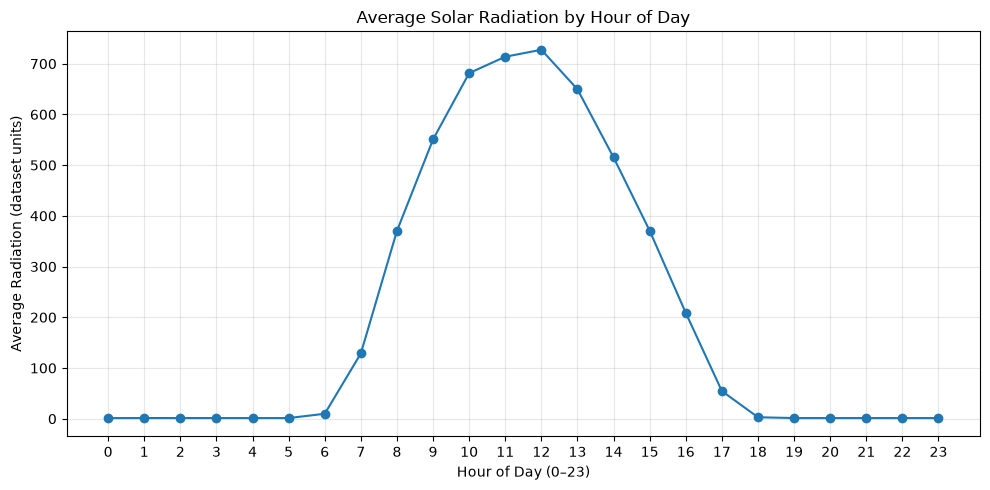

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_stats.index,
    hourly_stats["Average_Radiation"],
    marker="o"
)

plt.title("Average Solar Radiation by Hour of Day")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Average Radiation (dataset units)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../plots/05_hourly_radiation.png", dpi=200)
plt.show()

In [26]:
best_hour = hourly_stats["Average_Radiation"].idxmax()
best_average = hourly_stats["Average_Radiation"].max()

print("Hour with highest average radiation:", best_hour)
print("Highest hourly average radiation:", round(best_average, 2))

Hour with highest average radiation: 12
Highest hourly average radiation: 727.47


In [3]:
highest_readings = data.nlargest(10, "Radiation")

display(
    highest_readings[
        ["Datetime", "Radiation", "Temperature",
         "Humidity", "Pressure", "Speed"]
    ]
)

NameError: name 'data' is not defined

In [2]:
q1 = data["Radiation"].quantile(0.25)
q3 = data["Radiation"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = data[
    (data["Radiation"] < lower_bound)
    | (data["Radiation"] > upper_bound)
]

print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Potential outliers:", len(outliers))

display(
    outliers[
        ["Datetime", "Radiation", "Temperature",
         "Humidity", "Pressure", "Speed"]
    ].sort_values("Radiation", ascending=False).head(10)
)

NameError: name 'data' is not defined

In [1]:
hourly_quartiles = data.groupby("Hour")["Radiation"].agg(
    Q1=lambda values: values.quantile(0.25),
    Q3=lambda values: values.quantile(0.75)
)

hourly_quartiles["IQR"] = (
    hourly_quartiles["Q3"] - hourly_quartiles["Q1"]
)

hourly_quartiles["Upper_Bound"] = (
    hourly_quartiles["Q3"] + 1.5 * hourly_quartiles["IQR"]
)

data["Hourly_Upper_Bound"] = data["Hour"].map(
    hourly_quartiles["Upper_Bound"]
)

hourly_outliers = data[
    data["Radiation"] > data["Hourly_Upper_Bound"]
]

print("Potential outliers using hourly limits:", len(hourly_outliers))

display(
    hourly_outliers[
        ["Datetime", "Hour", "Radiation", "Hourly_Upper_Bound"]
    ].sort_values("Radiation", ascending=False).head(10)
)

NameError: name 'data' is not defined

In [30]:
data["Month"] = data["Datetime"].dt.month

grouped = data.groupby(["Month", "Hour"])["Radiation"]

q1 = grouped.transform(lambda values: values.quantile(0.25))
q3 = grouped.transform(lambda values: values.quantile(0.75))

iqr = q3 - q1

data["MonthHour_Upper_Bound"] = q3 + 1.5 * iqr

month_hour_outliers = data[
    data["Radiation"] > data["MonthHour_Upper_Bound"]
]

print("Potential outliers using month-hour limits:",
      len(month_hour_outliers))

display(
    month_hour_outliers[
        ["Datetime", "Hour", "Radiation",
         "MonthHour_Upper_Bound"]
    ].sort_values("Radiation", ascending=False).head(10)
)

Potential outliers using month-hour limits: 610


,Datetime,Hour,Radiation,MonthHour_Upper_Bound
938,2016-09-04 10:55:14,10,1368.35,1269.87125
22131,2016-11-21 11:40:02,11,1239.27,1142.04250
20124,2016-11-14 12:15:01,12,1230.56,1155.79000
20418,2016-11-15 12:45:02,12,1189.26,1155.79000
16385,2016-11-01 12:20:18,12,1179.95,1155.79000
22130,2016-11-21 11:35:02,11,1154.65,1142.04250
20108,2016-11-14 10:55:05,10,1098.63,1038.47250
16343,2016-11-01 08:50:21,8,828.53,719.35625
32590,2016-12-31 16:00:02,16,552.33,537.27875
1574,2016-09-06 17:10:25,17,468.75,331.99625


In [ ]:
daily_stats.to_csv(
    "../report/daily_radiation_summary.csv",
    index_label="Date"
)

print("Daily statistics saved successfully!")